## Import Required Libraries

In [36]:
import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from pathlib import Path
import shutil
from ultralytics import YOLO
from pathlib import Path
import numpy as np

## Define Plate Detection Dataset Paths

In [2]:
plate_train_path = Path("../data/plate_train")
plate_validation_path = Path("../data/plate_validation")
plate_test_path = Path("../data/plate_test")

## Inspect Plate Detection Dataset

In [3]:
files = list(plate_train_path.iterdir())

for file in files[:20]:
    print(file.name)

day_13358.jpg
day_09499.xml
day_14437.jpg
day_15729.jpg
day_06972.xml
day_09300.jpg
day_06033.jpg
day_10889.jpg
day_16220.jpg
night (3985).xml
night (2697).xml
day_10651.jpg
day_01984.jpg
night (1812).xml
day_04803.xml
day_00324.jpg
night (879).xml
day_16546.jpg
day_09466.jpg
day_06755.jpg


## Inspect Plate Annotation XML

In [4]:
sample_xml = plate_train_path / "day_09499.xml"

tree = ET.parse(sample_xml)
root = tree.getroot()

print("Root tag:", root.tag)

for child in root:
    print(child.tag, child.text)

Root tag: annotation
filename 5831.jpg
object None
object None
object None
object None
object None
object None
object None
object None
object None
folder true_all_images


In [5]:
for obj in root.findall("object"):
    print("Object label:", obj.find("name").text)

    box = obj.find("bndbox")

    print("xmin:", box.find("xmin").text)
    print("ymin:", box.find("ymin").text)
    print("xmax:", box.find("xmax").text)
    print("ymax:", box.find("ymax").text)

    print("---")

Object label: کل ناحیه پلاک
xmin: 160
ymin: 263
xmax: 317
ymax: 299
---
Object label: 5
xmin: 177
ymin: 267
xmax: 193
ymax: 293
---
Object label: 1
xmin: 194
ymin: 267
xmax: 207
ymax: 293
---
Object label: ص
xmin: 207
ymin: 270
xmax: 234
ymax: 292
---
Object label: 1
xmin: 237
ymin: 268
xmax: 250
ymax: 294
---
Object label: 1
xmin: 252
ymin: 268
xmax: 264
ymax: 294
---
Object label: 5
xmin: 264
ymin: 268
xmax: 281
ymax: 294
---
Object label: 6
xmin: 283
ymin: 272
xmax: 299
ymax: 296
---
Object label: 3
xmin: 299
ymin: 272
xmax: 315
ymax: 296
---


## Visualize License Plate Bounding Box

Image path: ../data/plate_train/day_09499.jpg
Exists: True


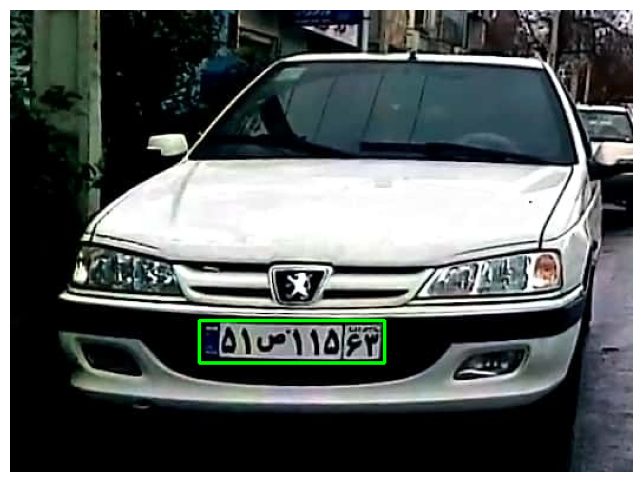

In [ ]:
sample_xml = plate_train_path / "day_09499.xml"

tree = ET.parse(sample_xml)
root = tree.getroot()

image_path = sample_xml.with_suffix(".jpg")
print("Image path:", image_path)
print("Exists:", image_path.exists())

image = cv2.imread(str(image_path))

for obj in root.findall("object"):
    label = obj.find("name").text

    if label == "کل ناحیه پلاک":
        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        cv2.rectangle(image,
            (xmin, ymin),
            (xmax, ymax),
            (0, 255, 0),
            2
        )

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Debug Plate Image Path

In [7]:
print("XML path:", sample_xml)
print("Image filename from XML:", image_filename)
print("Constructed image path:", image_path)
print("Image path exists:", image_path.exists())

XML path: ../data/plate_train/day_09499.xml
Image filename from XML: 5831.jpg
Constructed image path: ../data/plate_train/5831.jpg
Image path exists: False


## Convert Plate Bounding Box to YOLO Format

In [19]:
def convert_plate_xml_to_yolo(xml_path, image_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    image = cv2.imread(str(image_path))
    image_height, image_width = image.shape[:2]

    for obj in root.findall("object"):
        label = obj.find("name").text

        if label != "کل ناحیه پلاک":
            continue

        box = obj.find("bndbox")

        xmin = int(float(box.find("xmin").text))
        ymin = int(float(box.find("ymin").text))
        xmax = int(float(box.find("xmax").text))
        ymax = int(float(box.find("ymax").text))
        
        xmin = max(0, min(xmin, image_width))
        xmax = max(0, min(xmax, image_width))
        ymin = max(0, min(ymin, image_height))
        ymax = max(0, min(ymax, image_height))

        if xmin >= xmax or ymin >= ymax:
            return None

        x_center = ((xmin + xmax) / 2) / image_width
        y_center = ((ymin + ymax) / 2) / image_height

        width = (xmax - xmin) / image_width
        height = (ymax - ymin) / image_height

        return [0, x_center, y_center, width, height]

## Test YOLO Plate Annotation Conversion

In [20]:
annotation = convert_plate_xml_to_yolo(
    sample_xml,
    image_path
)

print(annotation)

[0, 0.45170454545454547, 0.7168367346938775, 0.29734848484848486, 0.09183673469387756]


## Prepare YOLO Plate Detection Dataset Split

In [21]:
def prepare_plate_yolo_split(source_dir, output_dir, split_name):
    source_dir = Path(source_dir)
    output_dir = Path(output_dir)

    images_dir = output_dir / "images" / split_name
    labels_dir = output_dir / "labels" / split_name

    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    xml_files = sorted(source_dir.glob("*.xml"))

    for xml_path in xml_files:
        image_path = xml_path.with_suffix(".jpg")

        if not image_path.exists():
            continue

        annotation = convert_plate_xml_to_yolo(
            xml_path,
            image_path
        )

        if annotation is None:
            continue

        shutil.copy(
            image_path,
            images_dir / image_path.name
        )

        label_path = labels_dir / f"{xml_path.stem}.txt"

        class_id, x_center, y_center, width, height = annotation

        with open(label_path, "w") as f:
            f.write(
                f"{class_id} {x_center} {y_center} {width} {height}\n"
            )

## Build YOLO Plate Detection Dataset

In [22]:
plate_yolo_output = "../data/plate_yolo_dataset"

prepare_plate_yolo_split(
    "../data/plate_train",
    plate_yolo_output,
    "train"
)

prepare_plate_yolo_split(
    "../data/plate_validation",
    plate_yolo_output,
    "validation"
)

prepare_plate_yolo_split(
    "../data/plate_test",
    plate_yolo_output,
    "test"
)

## Verify YOLO Plate Dataset

In [ ]:
plate_yolo_path = Path("../data/plate_yolo_dataset")

train_images = list((plate_yolo_path / "images/train").glob("*.jpg"))
train_labels = list((plate_yolo_path / "labels/train").glob("*.txt"))

validation_images = list((plate_yolo_path / "images/validation").glob("*.jpg"))
validation_labels = list((plate_yolo_path / "labels/validation").glob("*.txt"))

test_images = list((plate_yolo_path / "images/test").glob("*.jpg"))
test_labels = list((plate_yolo_path / "labels/test").glob("*.txt"))

print("Train:", len(train_images), len(train_labels))
print("Validation:", len(validation_images), len(validation_labels))
print("Test:", len(test_images), len(test_labels))

Train: 14671 14671
Validation: 2120 2120
Test: 4176 4176


## Inspect Sample YOLO Plate Label

In [24]:
sample_label = train_labels[0]

with open(sample_label, "r") as f:
    print(f.read())

0 0.503515625 0.15677083333333333 0.13046875 0.059375



## Load Pretrained YOLO Model

In [26]:
plate_detector = YOLO("yolo11n.pt")

/Users/parsa.h/Python/Deep Learning/ai1_env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Train License Plate Detector

In [27]:
results = plate_detector.train(
    data="../data/plate_yolo_dataset/data.yaml",
    epochs=3,
    imgsz=640,
    batch=16,
    device="mps"
)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.9.6 torch-2.8.0 MPS (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../data/plate_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosai

## Locate Trained Plate Detector

In [29]:
runs_path = Path("runs/detect")

for path in sorted(runs_path.glob("train*/weights/best.pt")):
    print(path)

runs/detect/train-10/weights/best.pt
runs/detect/train-12/weights/best.pt
runs/detect/train-13/weights/best.pt
runs/detect/train-8/weights/best.pt


## Load Trained Plate Detector

In [30]:
plate_detector = YOLO(
    "runs/detect/train-13/weights/best.pt"
)

## Find Latest YOLO Training Run

In [ ]:


best_models = list(Path("runs/detect").glob("train*/weights/best.pt"))

latest_model = max(
    best_models,
    key=lambda path: path.stat().st_mtime
)

print(latest_model)

runs/detect/train-13/weights/best.pt


## Test License Plate Detector on Vehicle Image

In [ ]:
test_image = "../data/plate_test/day_00010.jpg"

results = plate_detector.predict(
    source=test_image,
    conf=0.5
)



image 1/1 /Users/parsa.h/Python/Deep Learning/iranian-license-plate-ocr/src/../data/plate_test/day_00010.jpg: 480x640 (no detections), 55.5ms
Speed: 3.3ms preprocess, 55.5ms inference, 0.5ms postprocess per image at shape (1, 3, 480, 640)


## Test Plate Detector with Lower Confidence

In [37]:
results = plate_detector.predict(
    source=test_image,
    conf=0.25
)


image 1/1 /Users/parsa.h/Python/Deep Learning/iranian-license-plate-ocr/src/../data/plate_test/day_00010.jpg: 480x640 1 license_plate, 88.6ms
Speed: 22.1ms preprocess, 88.6ms inference, 16.2ms postprocess per image at shape (1, 3, 480, 640)


## Visualize Plate Detection Result

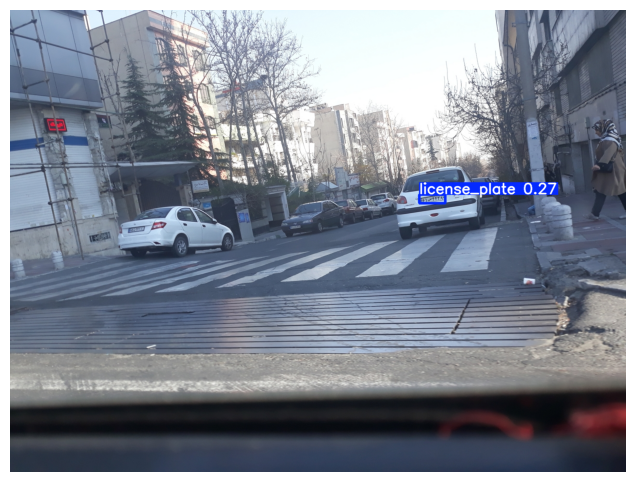

In [38]:
result = results[0]

annotated_image = result.plot()

plt.figure(figsize=(10, 6))
plt.imshow(
    cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
)
plt.axis("off")
plt.show()

## Crop Detected License Plate

In [42]:
image = cv2.imread(test_image)

boxes = result.boxes.xyxy.cpu().numpy()
confidences = result.boxes.conf.cpu().numpy()

plate_crops = []

for box, confidence in zip(boxes, confidences):
    xmin, ymin, xmax, ymax = map(int, box)

    plate_crop = image[
        ymin:ymax,
        xmin:xmax
    ]

    plate_crops.append(plate_crop)

    print("Confidence:", confidence)

Confidence: 0.26769033


## Visualize Cropped License Plate

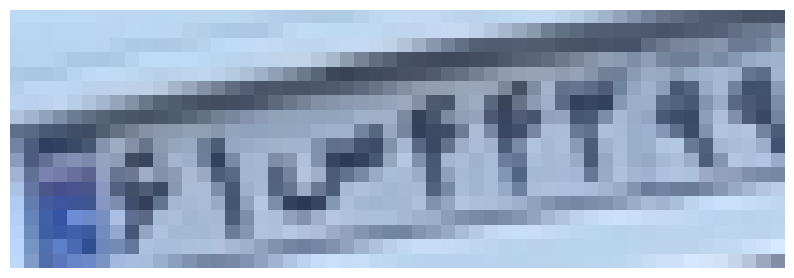

In [43]:
plt.figure(figsize=(10, 4))

for i, plate_crop in enumerate(plate_crops):
    plt.subplot(1, len(plate_crops), i + 1)

    plt.imshow(
        cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB)
    )

    plt.axis("off")

plt.show()